In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("client_data.csv")
print("Dataset Shape:", df.shape)
print("First 5 Rows:")
print(df.head())

Dataset Shape: (2500, 25)
First 5 Rows:
   client_id inquiry_source  inquiry_source_score  mentioned_business_income  \
0          1             ad                     0                          1   
1          2         walkin                     1                          1   
2          3             ad                     0                          0   
3          4             ad                     0                          1   
4          5       referral                     2                          0   

   response_time_hours  requested_pricing_info  lead_hot  years_as_client  \
0                  3.0                       1         1              0.9   
1                  3.8                       1         1              0.5   
2                 11.6                       0         0              1.1   
3                  2.5                       0         0              1.9   
4                 12.2                       1         1              5.0   

   filing_comple

In [11]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['client_id', 'inquiry_source', 'inquiry_source_score', 'mentioned_business_income', 'response_time_hours', 'requested_pricing_info', 'lead_hot', 'years_as_client', 'filing_complexity_score', 'addons_purchased', 'referrals_given', 'num_income_sources', 'lifetime_revenue', 'next_year_income', 'past_filing_errors', 'time_spent_selfiling_minutes', 'deductions_claimed_count', 'dependents_count', 'support_contacts_count', 'premium_upgrade', 'staff_hours_spent', 'forms_filed_count', 'revisions_count', 'current_fee_charged', 'fair_fee']


In [12]:
print("\nData Types:")
print(df.dtypes)


Data Types:
client_id                         int64
inquiry_source                   object
inquiry_source_score              int64
mentioned_business_income         int64
response_time_hours             float64
requested_pricing_info            int64
lead_hot                          int64
years_as_client                 float64
filing_complexity_score           int64
addons_purchased                  int64
referrals_given                   int64
num_income_sources                int64
lifetime_revenue                float64
next_year_income                float64
past_filing_errors                int64
time_spent_selfiling_minutes    float64
deductions_claimed_count          int64
dependents_count                  int64
support_contacts_count            int64
premium_upgrade                   int64
staff_hours_spent               float64
forms_filed_count                 int64
revisions_count                   int64
current_fee_charged             float64
fair_fee                   

In [13]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
client_id                       0
inquiry_source                  0
inquiry_source_score            0
mentioned_business_income       0
response_time_hours             0
requested_pricing_info          0
lead_hot                        0
years_as_client                 0
filing_complexity_score         0
addons_purchased                0
referrals_given                 0
num_income_sources              0
lifetime_revenue                0
next_year_income                0
past_filing_errors              0
time_spent_selfiling_minutes    0
deductions_claimed_count        0
dependents_count                0
support_contacts_count          0
premium_upgrade                 0
staff_hours_spent               0
forms_filed_count               0
revisions_count                 0
current_fee_charged             0
fair_fee                        0
dtype: int64


In [ ]:

target_column = "next_year_revenue"
df = df.dropna()
print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (2500, 25)


In [15]:
print(df.columns.tolist())

['client_id', 'inquiry_source', 'inquiry_source_score', 'mentioned_business_income', 'response_time_hours', 'requested_pricing_info', 'lead_hot', 'years_as_client', 'filing_complexity_score', 'addons_purchased', 'referrals_given', 'num_income_sources', 'lifetime_revenue', 'next_year_income', 'past_filing_errors', 'time_spent_selfiling_minutes', 'deductions_claimed_count', 'dependents_count', 'support_contacts_count', 'premium_upgrade', 'staff_hours_spent', 'forms_filed_count', 'revisions_count', 'current_fee_charged', 'fair_fee']


In [16]:
correlations = (
    df.select_dtypes(include=np.number)
      .corr()["next_year_income"]
      .drop("next_year_income")
      .sort_values(key=abs, ascending=False)
)

print(correlations)

lifetime_revenue                0.961217
filing_complexity_score         0.880922
fair_fee                        0.804298
staff_hours_spent               0.760646
current_fee_charged             0.557429
years_as_client                 0.375893
forms_filed_count               0.364102
premium_upgrade                 0.261190
addons_purchased                0.243595
num_income_sources              0.117220
referrals_given                 0.091255
mentioned_business_income       0.043788
past_filing_errors             -0.018579
requested_pricing_info          0.018464
dependents_count               -0.013446
response_time_hours            -0.012331
client_id                      -0.012054
inquiry_source_score            0.011593
lead_hot                        0.011391
revisions_count                -0.008091
time_spent_selfiling_minutes   -0.005498
deductions_claimed_count       -0.003559
support_contacts_count          0.003191
Name: next_year_income, dtype: float64


In [17]:
target_column = "next_year_income"
features = [
    col
    for col in df.select_dtypes(include=np.number).columns
    if col not in ["client_id", target_column]
]
print("\nFeatures:")
print(features)
print("\nTarget:")
print(target_column)


Features:
['inquiry_source_score', 'mentioned_business_income', 'response_time_hours', 'requested_pricing_info', 'lead_hot', 'years_as_client', 'filing_complexity_score', 'addons_purchased', 'referrals_given', 'num_income_sources', 'lifetime_revenue', 'past_filing_errors', 'time_spent_selfiling_minutes', 'deductions_claimed_count', 'dependents_count', 'support_contacts_count', 'premium_upgrade', 'staff_hours_spent', 'forms_filed_count', 'revisions_count', 'current_fee_charged', 'fair_fee']

Target:
next_year_income


In [18]:
X = df[features].values
y = df[target_column].values

In [19]:

print("\nMean:")
print(df[features + [target_column]].mean())
print("\nStandard Deviation:")
print(df[features + [target_column]].std())
print("\nCorrelation Matrix:")
print(df[features + [target_column]].corr())
print("\nCorrelation with fair_fee:")
print(
    df[features + [target_column]]
    .corr()["next_year_income"]
    .sort_values(ascending=False)
)



Mean:
inquiry_source_score                0.904000
mentioned_business_income           0.394800
response_time_hours                 5.887800
requested_pricing_info              0.485200
lead_hot                            0.500000
years_as_client                     5.003320
filing_complexity_score             5.482000
addons_purchased                    1.254000
referrals_given                     0.774400
num_income_sources                  3.024400
lifetime_revenue                10171.641688
past_filing_errors                  0.882400
time_spent_selfiling_minutes       46.743640
deductions_claimed_count            5.464400
dependents_count                    2.018800
support_contacts_count              1.505600
premium_upgrade                     0.864400
staff_hours_spent                   5.159160
forms_filed_count                   6.023600
revisions_count                     0.602400
current_fee_charged              1981.673680
fair_fee                         2328.097228
nex

In [20]:
print(features)

['inquiry_source_score', 'mentioned_business_income', 'response_time_hours', 'requested_pricing_info', 'lead_hot', 'years_as_client', 'filing_complexity_score', 'addons_purchased', 'referrals_given', 'num_income_sources', 'lifetime_revenue', 'past_filing_errors', 'time_spent_selfiling_minutes', 'deductions_claimed_count', 'dependents_count', 'support_contacts_count', 'premium_upgrade', 'staff_hours_spent', 'forms_filed_count', 'revisions_count', 'current_fee_charged', 'fair_fee']


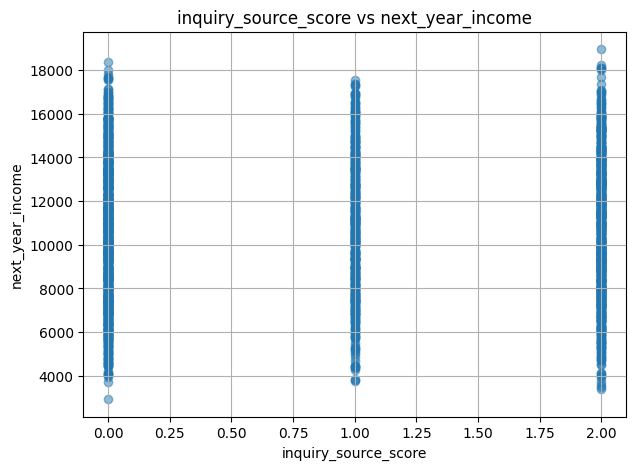

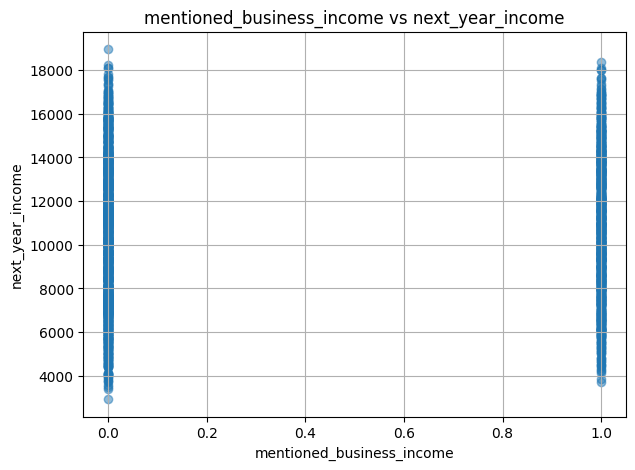

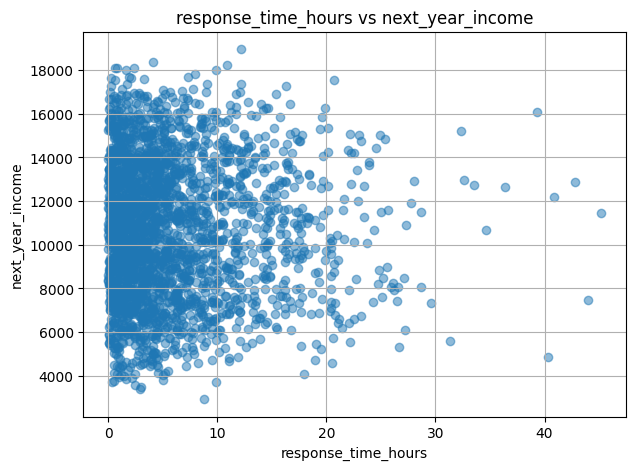

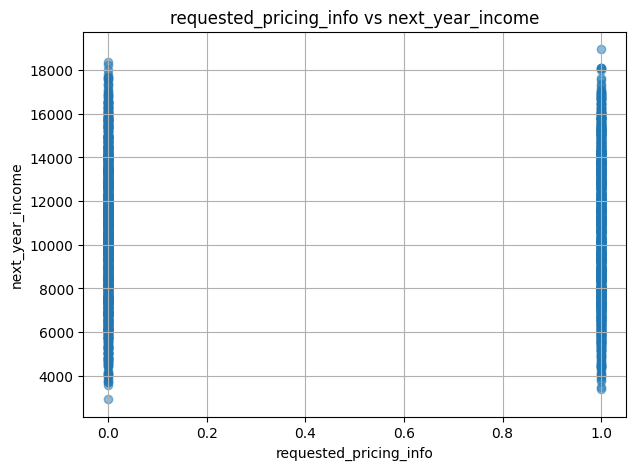

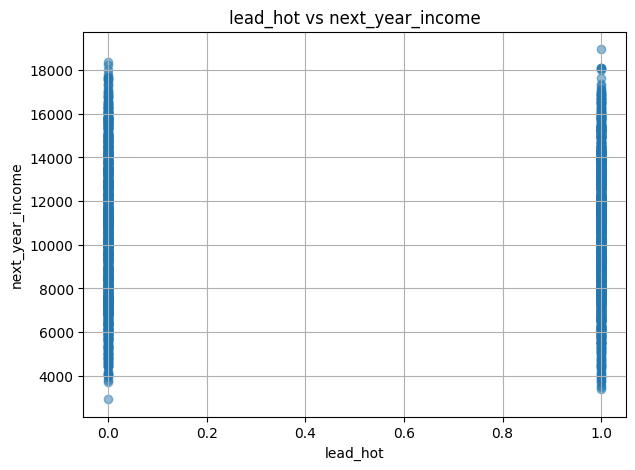

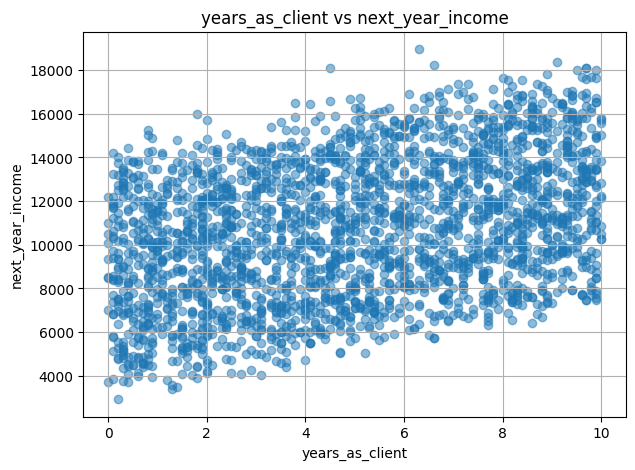

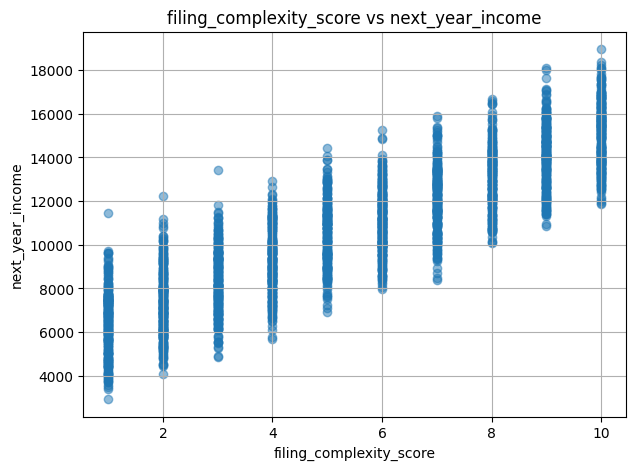

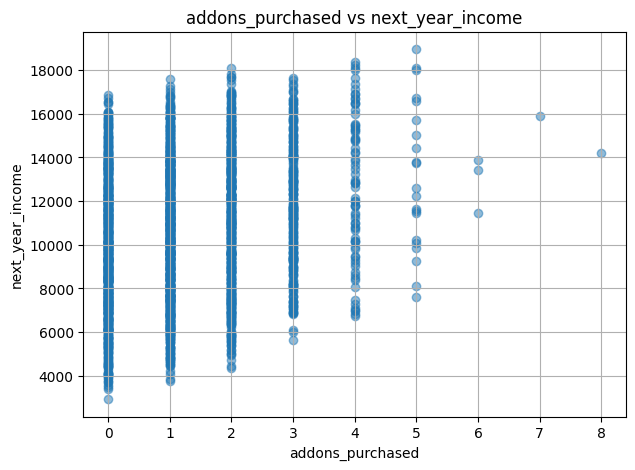

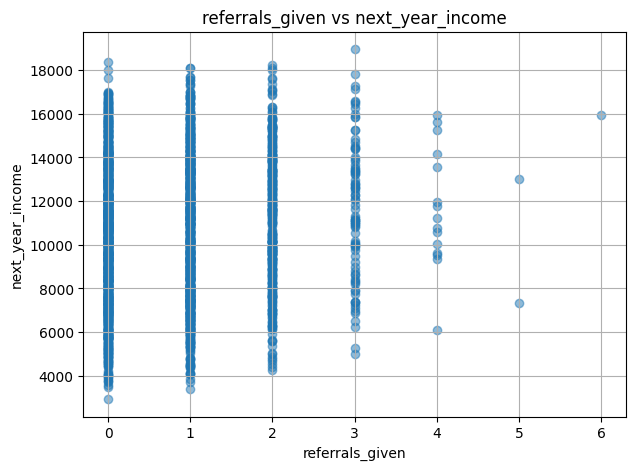

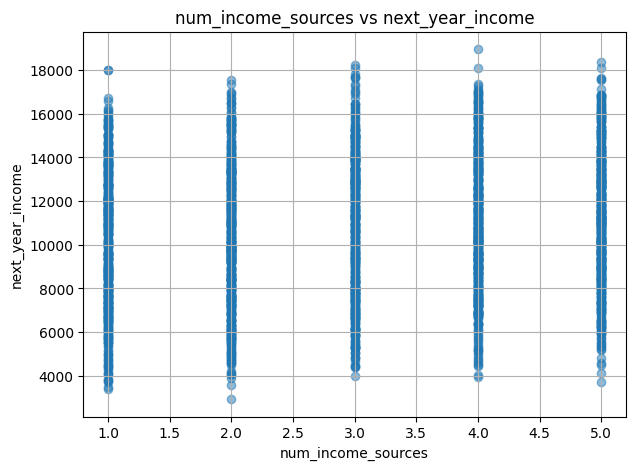

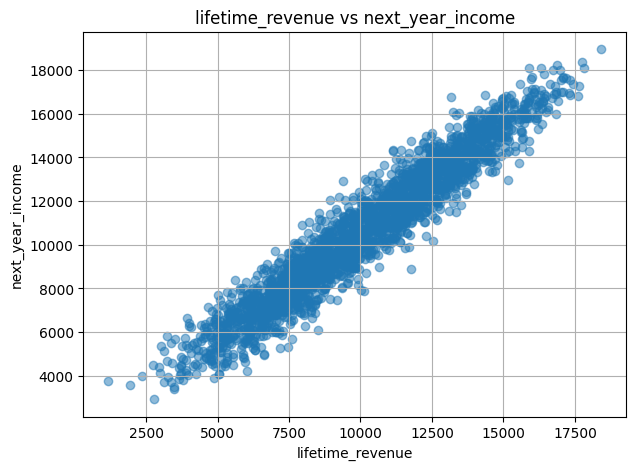

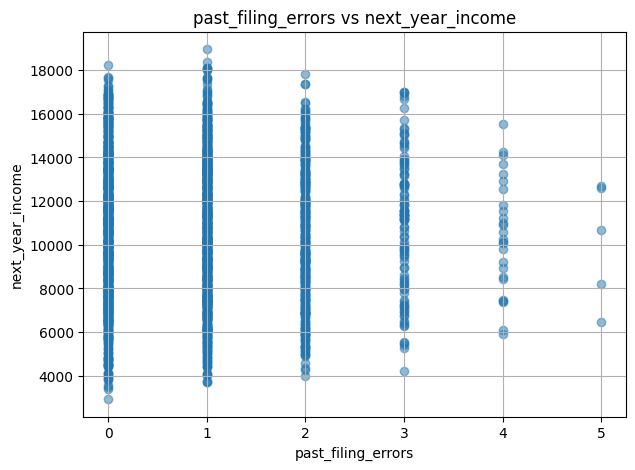

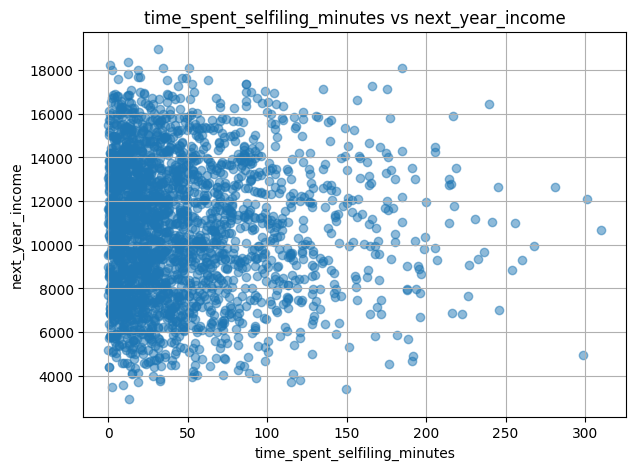

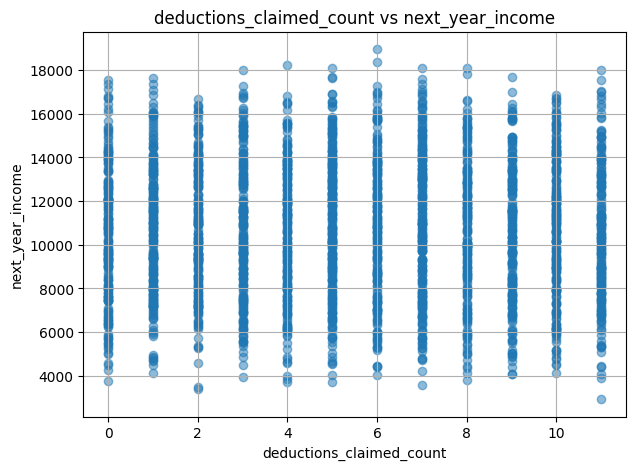

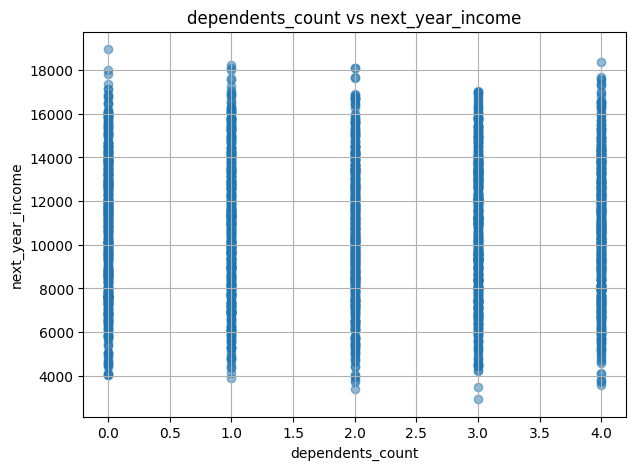

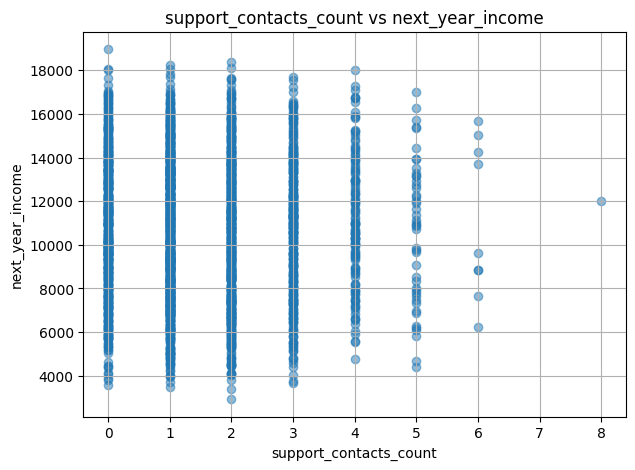

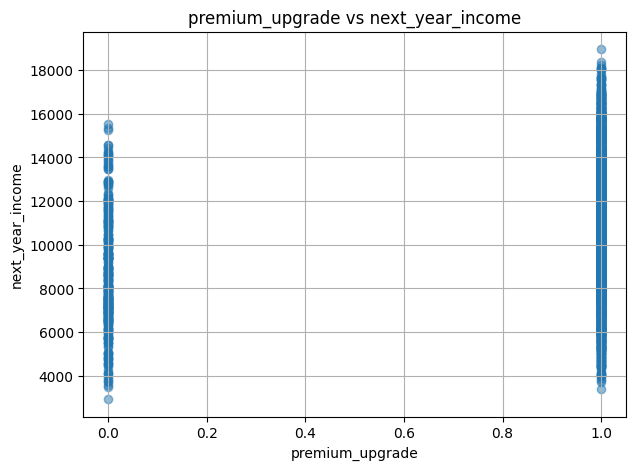

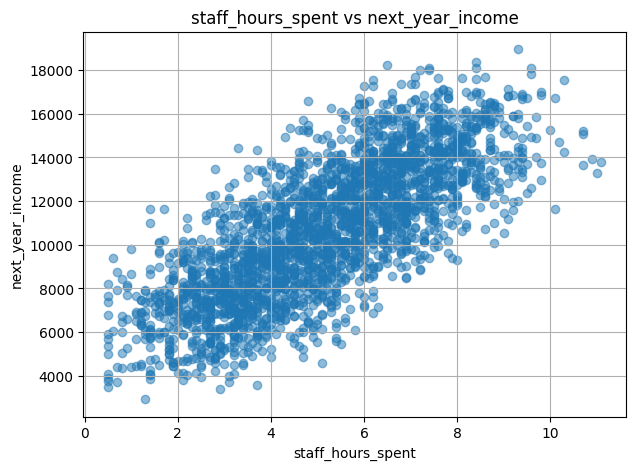

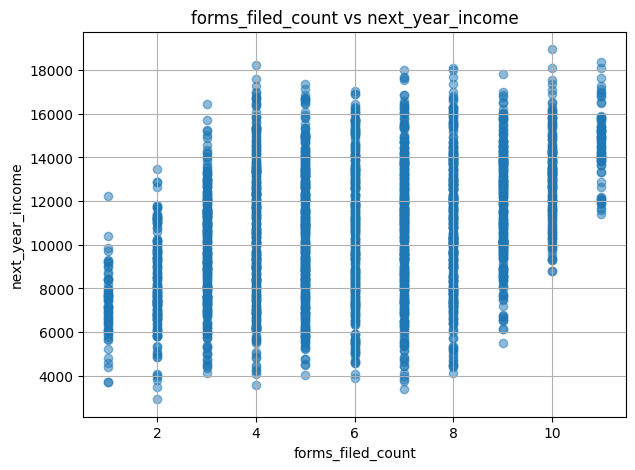

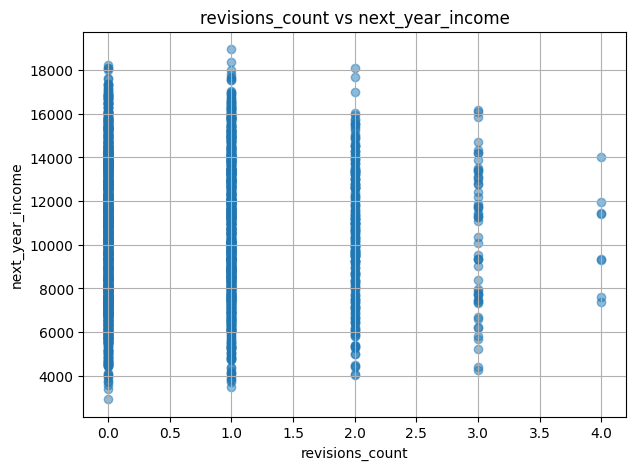

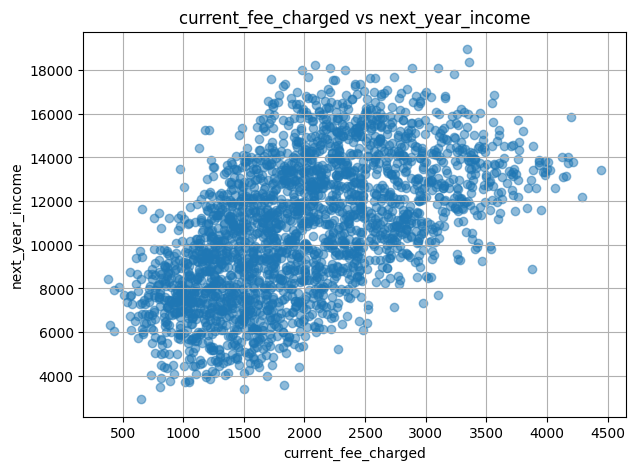

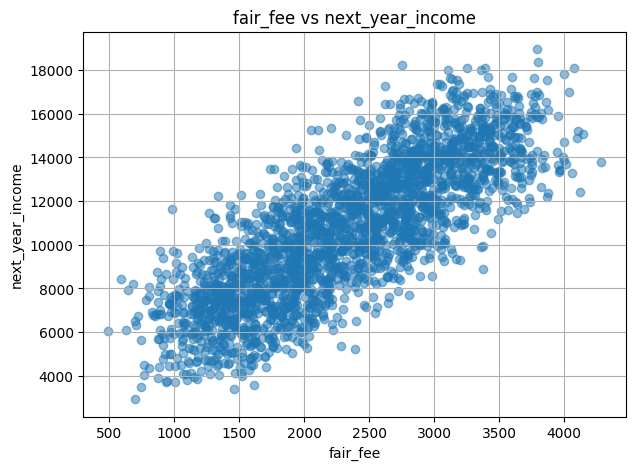

In [21]:

for feature in features:
    plt.figure(figsize=(7, 5))
    plt.scatter(
        df[feature],
        df[target_column],
        alpha=0.5
    )
    plt.xlabel(feature)
    plt.ylabel("next_year_income")
    plt.title(
        f"{feature} vs next_year_income"
    )
    plt.grid(True)
    plt.show()


In [22]:
np.random.seed(42)
indices = np.random.permutation(len(X))
X = X[indices]
y = y[indices]
total_samples = len(X)
train_end = int(0.60 * total_samples)
validation_end = int(0.80 * total_samples)
X_train = X[:train_end]
y_train = y[:train_end]
X_validation = X[train_end:validation_end]
y_validation = y[train_end:validation_end]
X_test = X[validation_end:]
y_test = y[validation_end:]


In [23]:
print("Total samples:", total_samples)
print(
    "Training samples:",
    len(X_train)
)
print(
    "Validation samples:",
    len(X_validation)
)
print(
    "Testing samples:",
    len(X_test)
)


Total samples: 2500
Training samples: 1500
Validation samples: 500
Testing samples: 500


In [24]:

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1
X_train_scaled = (
    X_train - X_mean
) / X_std
X_validation_scaled = (
    X_validation - X_mean
) / X_std
X_test_scaled = (
    X_test - X_mean
) / X_std

In [25]:
def add_bias(X):
    
    return np.c_[
        np.ones(X.shape[0]),
        X
    ]
X_train_b = add_bias(X_train_scaled)
X_validation_b = add_bias(
    X_validation_scaled
)
X_test_b = add_bias(
    X_test_scaled
)

In [26]:
def gradient_descent(
    X,
    y,
    learning_rate=0.01,
    iterations=2000
):
    m = len(y)
    weights = np.zeros(
        X.shape[1]
    )
    cost_history = []
    for i in range(iterations):
        predictions = X @ weights
        errors = predictions - y
        gradient = (
            1 / m
        ) * (
            X.T @ errors
        )
        weights = (
            weights
            - learning_rate * gradient
        )
        cost = (
            1 / (2 * m)
        ) * np.sum(
            errors ** 2
        )
        cost_history.append(cost)
    return weights, cost_history

In [27]:

start_time = time.time()
gd_weights, cost_history = gradient_descent(
    X_train_b,
    y_train,
    learning_rate=0.01,
    iterations=2000
)
gd_training_time = (
    time.time() - start_time
)

In [28]:
linear_weights = gd_weights.copy()
linear_mean = X_mean.copy()
linear_std = X_std.copy()

In [29]:
gd_train_predictions = (
    X_train_b @ gd_weights
)
gd_validation_predictions = (
    X_validation_b @ gd_weights
)
gd_test_predictions = (
    X_test_b @ gd_weights
)


In [30]:
start_time = time.time()
normal_weights = (
    np.linalg.pinv(
        X_train_b.T @ X_train_b
    )
    @ X_train_b.T
    @ y_train
)
normal_training_time = (
    time.time() - start_time
)


In [31]:
normal_train_predictions = (
    X_train_b @ normal_weights
)
normal_validation_predictions = (
    X_validation_b @ normal_weights
)
normal_test_predictions = (
    X_test_b @ normal_weights
)


In [32]:
print(
    "Gradient Descent:",
    gd_training_time,
    "seconds"
)
print(
    "Normal Equation:",
    normal_training_time,
    "seconds"
)

Gradient Descent: 0.09917092323303223 seconds
Normal Equation: 0.042136430740356445 seconds


In [33]:
print("\nGradient Descent Weights:")
for name, weight in zip(
    ["Intercept"] + features,
    gd_weights
):
    print(
        name,
        ":",
        weight
    )
print("\nNormal Equation Weights:")
for name, weight in zip(
    ["Intercept"] + features,
    normal_weights
):
    print(
        name,
        ":",
        weight
    )



Gradient Descent Weights:
Intercept : 10746.186826638395
inquiry_source_score : -4.550344120253232
mentioned_business_income : -5.744573775132943
response_time_hours : 14.430177210291959
requested_pricing_info : -8.788537368460512
lead_hot : 17.586116728242253
years_as_client : 902.2874075495257
filing_complexity_score : 1865.9398803552688
addons_purchased : 534.0292926357585
referrals_given : 208.43588179209002
num_income_sources : 248.85629897217478
lifetime_revenue : 770.4235246492291
past_filing_errors : -0.04154439820615579
time_spent_selfiling_minutes : -5.218607838067596
deductions_claimed_count : -7.3782712030056965
dependents_count : 4.729183308107564
support_contacts_count : -12.095781038542455
premium_upgrade : 18.94765790606192
staff_hours_spent : -31.823436136917156
forms_filed_count : -44.03441970890638
revisions_count : -50.668556841056464
current_fee_charged : -32.06111993184831
fair_fee : 331.84172294493465

Normal Equation Weights:
Intercept : 10746.186846666671
inqu

In [34]:
gd_train_mse = mean_squared_error(
    y_train,
    gd_train_predictions
)
gd_validation_mse = mean_squared_error(
    y_validation,
    gd_validation_predictions
)
gd_test_mse = mean_squared_error(
    y_test,
    gd_test_predictions
)
gd_test_r2 = r2_score(
    y_test,
    gd_test_predictions
)
print("\nGRADIENT DESCENT")
print(
    "Train MSE:",
    gd_train_mse
)
print(
    "Validation MSE:",
    gd_validation_mse
)
print(
    "Test MSE:",
    gd_test_mse
)
print(
    "Test R2:",
    gd_test_r2
)
normal_train_mse = mean_squared_error(
    y_train,
    normal_train_predictions
)
normal_validation_mse = mean_squared_error(
    y_validation,
    normal_validation_predictions
)
normal_test_mse = mean_squared_error(
    y_test,
    normal_test_predictions
)
normal_test_r2 = r2_score(
    y_test,
    normal_test_predictions
)
print("\nNORMAL EQUATION")
print(
    "Train MSE:",
    normal_train_mse
)
print(
    "Validation MSE:",
    normal_validation_mse
)
print(
    "Test MSE:",
    normal_test_mse
)
print(
    "Test R2:",
    normal_test_r2
)


GRADIENT DESCENT
Train MSE: 121477.68721289918
Validation MSE: 110995.81332946509
Test MSE: 118939.39091022052
Test R2: 0.9873738120927597

NORMAL EQUATION
Train MSE: 67780.04445241412
Validation MSE: 64860.33522831484
Test MSE: 64999.09531698698
Test R2: 0.9930999243817182


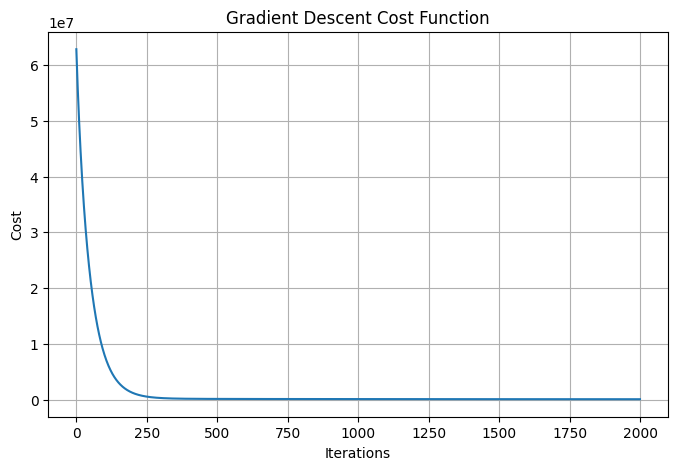

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(
    cost_history
)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title(
    "Gradient Descent Cost Function"
)
plt.grid(True)
plt.show()

In [36]:
target_column = "fair_fee"
numeric_df = df.select_dtypes(include=np.number)
numeric_df = numeric_df.drop(
    columns=["client_id"],
    errors="ignore"
)
correlations = (
    numeric_df.corr()["fair_fee"]
    .drop("fair_fee")
    .sort_values(
        key=abs,
        ascending=False
    )
)
print(correlations)
polynomial_feature = correlations.index[0]
correlation_value = correlations.iloc[0]
print(
    "Feature:",
    polynomial_feature
)
print(
    "Correlation with fair_fee:",
    correlation_value
)

staff_hours_spent               0.935922
filing_complexity_score         0.905032
current_fee_charged             0.851722
next_year_income                0.804298
lifetime_revenue                0.775658
forms_filed_count               0.536031
premium_upgrade                 0.283106
revisions_count                 0.146931
num_income_sources              0.139063
mentioned_business_income       0.036897
addons_purchased                0.024932
years_as_client                -0.022656
inquiry_source_score            0.016393
dependents_count               -0.014122
support_contacts_count          0.013199
referrals_given                -0.012705
requested_pricing_info         -0.011381
past_filing_errors             -0.010866
time_spent_selfiling_minutes   -0.006562
response_time_hours            -0.005702
lead_hot                       -0.000761
deductions_claimed_count        0.000211
Name: fair_fee, dtype: float64
Feature: staff_hours_spent
Correlation with fair_fee: 0.93592227147

In [37]:
X_poly = df[[polynomial_feature]].values
y_poly = df["next_year_income"].values
np.random.seed(42)
indices = np.random.permutation(len(X_poly))
X_poly = X_poly[indices]
y_poly = y_poly[indices]
n = len(X_poly)
train_end = int(0.60 * n)
validation_end = int(0.80 * n)
X_poly_train = X_poly[:train_end]
y_poly_train = y_poly[:train_end]
X_poly_validation = X_poly[
    train_end:validation_end
]
y_poly_validation = y_poly[
    train_end:validation_end
]
X_poly_test = X_poly[
    validation_end:
]
y_poly_test = y_poly[
    validation_end:
]
poly_mean = X_poly_train.mean(axis=0)
poly_std = X_poly_train.std(axis=0)
poly_std[poly_std == 0] = 1
X_poly_train_scaled = (
    X_poly_train - poly_mean
) / poly_std
X_poly_validation_scaled = (
    X_poly_validation - poly_mean
) / poly_std
degrees = [1, 2, 3, 5, 10]
train_errors = []
validation_errors = []
for degree in degrees:
    polynomial = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )
    X_train_degree = (
        polynomial.fit_transform(
            X_poly_train_scaled
        )
    )
    X_validation_degree = (
        polynomial.transform(
            X_poly_validation_scaled
        )
    )
    X_train_degree = add_bias(
        X_train_degree
    )
    X_validation_degree = add_bias(
        X_validation_degree
    )
    weights = np.linalg.pinv(
        X_train_degree.T
        @ X_train_degree
    ) @ X_train_degree.T @ y_poly_train
    train_predictions = (
        X_train_degree @ weights
    )

    validation_predictions = (
        X_validation_degree @ weights
    )
    train_mse = mean_squared_error(
        y_poly_train,
        train_predictions
    )
    validation_mse = mean_squared_error(
        y_poly_validation,
        validation_predictions
    )
    train_errors.append(train_mse)
    validation_errors.append(validation_mse)
print(
    "Feature Used:",
    polynomial_feature
)
print(
    "Correlation:",
    correlation_value
)
for degree, train_error, validation_error in zip(
    degrees,
    train_errors,
    validation_errors
):
    print(
        f"Degree {degree} | "
        f"Train MSE: {train_error:.4f} | "
        f"Validation MSE: {validation_error:.4f}"
    )

Feature Used: staff_hours_spent
Correlation: 0.9359222714728139
Degree 1 | Train MSE: 4218717.5168 | Validation MSE: 4076156.2697
Degree 2 | Train MSE: 4207035.0138 | Validation MSE: 4076581.0759
Degree 3 | Train MSE: 4084754.5582 | Validation MSE: 4055662.1626
Degree 5 | Train MSE: 4082026.4203 | Validation MSE: 4051051.1256
Degree 10 | Train MSE: 4068810.3249 | Validation MSE: 4079508.7241


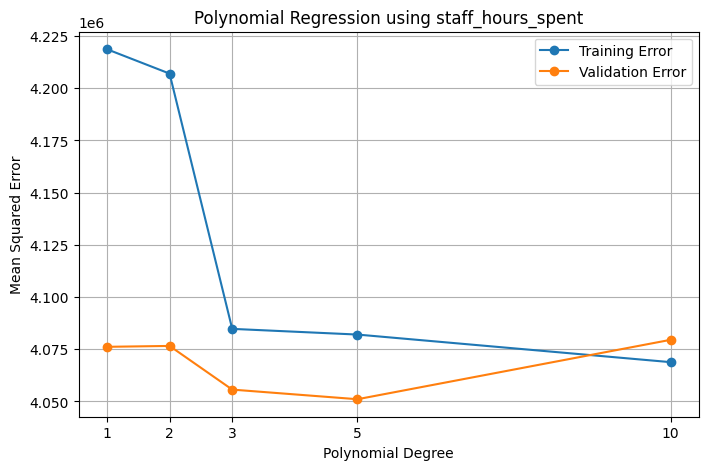

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    degrees,
    train_errors,
    marker="o",
    label="Training Error"
)
plt.plot(
    degrees,
    validation_errors,
    marker="o",
    label="Validation Error"
)
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title(
    f"Polynomial Regression using {polynomial_feature}"
)
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()



In [39]:
best_degree = degrees[
    np.argmin(validation_errors)
]
print("\nBest Polynomial Degree:",
      best_degree)
print(
    "Lowest Validation MSE:",
    min(validation_errors)
)


Best Polynomial Degree: 5
Lowest Validation MSE: 4051051.125574154


In [40]:
best_index = np.argmin(validation_errors)
best_degree = degrees[best_index]
print(
    f"Best Degree: {best_degree}"
)
print(
    f"Lowest Validation MSE: "
    f"{validation_errors[best_index]:.4f}"
)
overfitting_degree = None
for i in range(best_index + 1, len(degrees)):
    if validation_errors[i] > validation_errors[i - 1]:
        overfitting_degree = degrees[i]
        break
if overfitting_degree is not None:
    print(
        f"Overfitting starts at approximately "
        f"Degree {overfitting_degree}"
    )
else:
    print(
        "No clear overfitting point detected."
    )

Best Degree: 5
Lowest Validation MSE: 4051051.1256
Overfitting starts at approximately Degree 10


In [41]:
training_sizes = [50, 100, 200, 300, 400]
learning_train_errors = []
learning_validation_errors = []
best_degree = degrees[np.argmin(validation_errors)]
print("Polynomial Degree Used:", best_degree)
for size in training_sizes:
    X_subset = X_poly_train_scaled[:size]
    y_subset = y_poly_train[:size]
    polynomial = PolynomialFeatures(
        degree=best_degree,
        include_bias=False
    )
    X_subset_degree = polynomial.fit_transform(
        X_subset
    )
    X_validation_degree = polynomial.transform(
        X_poly_validation_scaled
    )
    X_subset_degree = add_bias(
        X_subset_degree
    )
    X_validation_degree = add_bias(
        X_validation_degree
    )
    weights = np.linalg.pinv(
        X_subset_degree.T @ X_subset_degree
    ) @ X_subset_degree.T @ y_subset

    # Predictions
    train_predictions = (
        X_subset_degree @ weights
    )
    validation_predictions = (
        X_validation_degree @ weights
    )
    train_mse = mean_squared_error(
        y_subset,
        train_predictions
    )
    validation_mse = mean_squared_error(
        y_poly_validation,
        validation_predictions
    )
    learning_train_errors.append(
        train_mse
    )

    learning_validation_errors.append(
        validation_mse
    )
    print(
        f"Training Size: {size} | "
        f"Train MSE: {train_mse:.4f} | "
        f"Validation MSE: {validation_mse:.4f}"
    )

Polynomial Degree Used: 5
Training Size: 50 | Train MSE: 3920423.8625 | Validation MSE: 16798989.2503
Training Size: 100 | Train MSE: 4993676.7718 | Validation MSE: 4732912.5817
Training Size: 200 | Train MSE: 4344323.1892 | Validation MSE: 4115794.4018
Training Size: 300 | Train MSE: 4141613.5974 | Validation MSE: 4100110.5505
Training Size: 400 | Train MSE: 4181491.2276 | Validation MSE: 4062853.8837


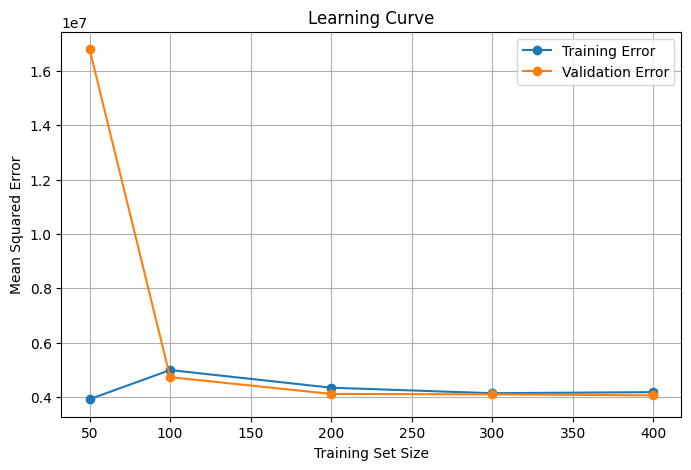

In [42]:
plt.figure(figsize=(8, 5))
plt.plot(
    training_sizes,
    learning_train_errors,
    marker="o",
    label="Training Error"
)
plt.plot(
    training_sizes,
    learning_validation_errors,
    marker="o",
    label="Validation Error"
)
plt.xlabel("Training Set Size")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)

plt.show()

In [43]:
for size, train_error, validation_error in zip(
    training_sizes,
    learning_train_errors,
    learning_validation_errors
):
    gap = validation_error - train_error
    print(
        f"Training Size: {size} | "
        f"Train MSE: {train_error:.4f} | "
        f"Validation MSE: {validation_error:.4f} | "
        f"Gap: {gap:.4f}"
    )
initial_gap = (
    learning_validation_errors[0]
    - learning_train_errors[0]
)
final_gap = (
    learning_validation_errors[-1]
    - learning_train_errors[-1]
)
initial_validation_error = learning_validation_errors[0]
final_validation_error = learning_validation_errors[-1]
if initial_gap > initial_validation_error * 0.5:
    print("Initial behavior: High variance")

elif (
    learning_train_errors[0] > 0.5 * initial_validation_error
    and abs(initial_gap) < 0.5 * initial_validation_error
):
    print("Initial behavior: High bias")
else:
    print("Initial behavior: Balanced bias-variance")
if final_gap < initial_gap:
    print(
        "As training size increases, "
        "the training and validation errors become closer."
    )
    print(
        "This indicates reduced variance and improved generalization."
    )
elif final_gap > initial_gap:
    print(
        "As training size increases, "
        "the gap between training and validation error increases."
    )
    print(
        "This indicates higher variance."
    )
else:
    print(
        "The bias-variance gap remains relatively stable."
    )
if final_validation_error < initial_validation_error:

    print(
        "Validation error decreases with more training data, "
        "indicating improved model performance."
    )
else:
    print(
        "Validation error does not improve significantly "
        "with additional training data, indicating possible high bias."
    )

Training Size: 50 | Train MSE: 3920423.8625 | Validation MSE: 16798989.2503 | Gap: 12878565.3878
Training Size: 100 | Train MSE: 4993676.7718 | Validation MSE: 4732912.5817 | Gap: -260764.1901
Training Size: 200 | Train MSE: 4344323.1892 | Validation MSE: 4115794.4018 | Gap: -228528.7874
Training Size: 300 | Train MSE: 4141613.5974 | Validation MSE: 4100110.5505 | Gap: -41503.0469
Training Size: 400 | Train MSE: 4181491.2276 | Validation MSE: 4062853.8837 | Gap: -118637.3439
Initial behavior: High variance
As training size increases, the training and validation errors become closer.
This indicates reduced variance and improved generalization.
Validation error decreases with more training data, indicating improved model performance.


In [44]:

gd_train_mse = mean_squared_error(
    y_train,
    gd_train_predictions
)

gd_validation_mse = mean_squared_error(
    y_validation,
    gd_validation_predictions
)

gd_test_mse = mean_squared_error(
    y_test,
    gd_test_predictions
)


# Normal Equation MSE

normal_train_mse = mean_squared_error(
    y_train,
    normal_train_predictions
)

normal_validation_mse = mean_squared_error(
    y_validation,
    normal_validation_predictions
)

normal_test_mse = mean_squared_error(
    y_test,
    normal_test_predictions
)


# ============================================================
# RESULTS
# ============================================================

print("\n========================================")
print("GRADIENT DESCENT vs NORMAL EQUATION")
print("========================================")

print("\nTraining MSE")
print("----------------------------------------")

print(
    f"Gradient Descent : {gd_train_mse:.4f}"
)

print(
    f"Normal Equation  : {normal_train_mse:.4f}"
)

print("\nValidation MSE")
print("----------------------------------------")

print(
    f"Gradient Descent : {gd_validation_mse:.4f}"
)

print(
    f"Normal Equation  : {normal_validation_mse:.4f}"
)

print("\nTest MSE")
print("----------------------------------------")

print(
    f"Gradient Descent : {gd_test_mse:.4f}"
)

print(
    f"Normal Equation  : {normal_test_mse:.4f}"
)

print("\nTraining Time")
print("----------------------------------------")

print(
    f"Gradient Descent : {gd_training_time:.6f} seconds"
)

print(
    f"Normal Equation  : {normal_training_time:.6f} seconds"
)

print("\nWeight Difference")
print("----------------------------------------")

weight_difference = np.linalg.norm(
    gd_weights - normal_weights
)

print(
    f"{weight_difference:.6f}"
)


GRADIENT DESCENT vs NORMAL EQUATION

Training MSE
----------------------------------------
Gradient Descent : 121477.6872
Normal Equation  : 67780.0445

Validation MSE
----------------------------------------
Gradient Descent : 110995.8133
Normal Equation  : 64860.3352

Test MSE
----------------------------------------
Gradient Descent : 118939.3909
Normal Equation  : 64999.0953

Training Time
----------------------------------------
Gradient Descent : 0.099171 seconds
Normal Equation  : 0.042136 seconds

Weight Difference
----------------------------------------
1388.987768


In [45]:
gd_train_r2 = r2_score(
    y_train,
    gd_train_predictions
)
gd_validation_r2 = r2_score(
    y_validation,
    gd_validation_predictions
)
gd_test_r2 = r2_score(
    y_test,
    gd_test_predictions
)
normal_train_r2 = r2_score(
    y_train,
    normal_train_predictions
)
normal_validation_r2 = r2_score(
    y_validation,
    normal_validation_predictions
)
normal_test_r2 = r2_score(
    y_test,
    normal_test_predictions
)
print("R-SQUARED COMPARISON")
print("\nTraining R²")
print(
    f"Gradient Descent : {gd_train_r2:.4f}"
)
print(
    f"Normal Equation  : {normal_train_r2:.4f}"
)
print("\nValidation R²")
print(
    f"Gradient Descent : {gd_validation_r2:.4f}"
)
print(
    f"Normal Equation  : {normal_validation_r2:.4f}"
)
print("\nTest R²")
print(
    f"Gradient Descent : {gd_test_r2:.4f}"
)
print(
    f"Normal Equation  : {normal_test_r2:.4f}"
)

R-SQUARED COMPARISON

Training R²
Gradient Descent : 0.9881
Normal Equation  : 0.9933

Validation R²
Gradient Descent : 0.9880
Normal Equation  : 0.9930

Test R²
Gradient Descent : 0.9874
Normal Equation  : 0.9931


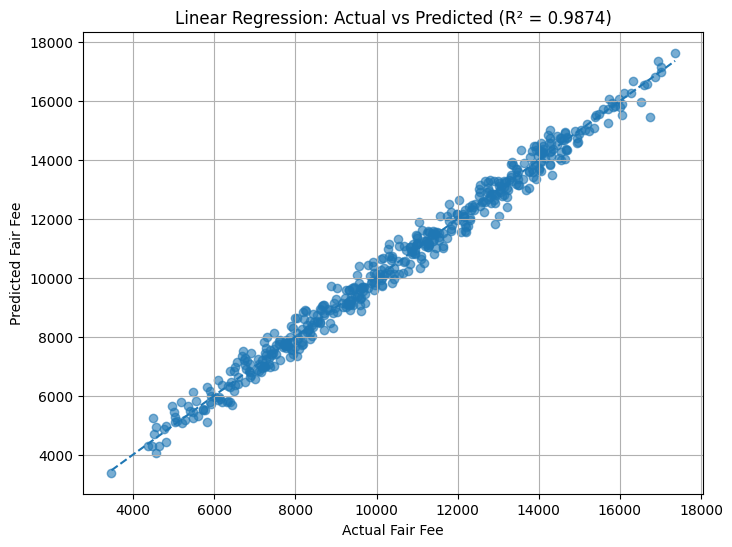

In [46]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    gd_test_predictions,
    alpha=0.6
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Fair Fee")
plt.ylabel("Predicted Fair Fee")
plt.title(f"Linear Regression: Actual vs Predicted (R² = {gd_test_r2:.4f})")
plt.grid(True)
plt.show()

In [47]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": gd_test_predictions,
    "Difference": y_test - gd_test_predictions
})

comparison.head(20)

,Actual,Predicted,Difference
0,14361.59,14376.370639,-14.780639
1,13053.65,12894.382908,159.267092
2,5181.59,5775.301647,-593.711647
3,8659.17,9032.820185,-373.650185
4,4962.88,5646.328379,-683.448379
5,9480.90,9364.665402,116.234598
6,14290.16,14302.563163,-12.403163
7,12347.26,12466.375206,-119.115206
8,16867.60,16818.913761,48.686239
9,7074.69,7241.715639,-167.025639


In [48]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np


gd_train_mse = mean_squared_error(
    y_train,
    gd_train_predictions
)

gd_validation_mse = mean_squared_error(
    y_validation,
    gd_validation_predictions
)

gd_test_mse = mean_squared_error(
    y_test,
    gd_test_predictions
)

gd_train_rmse = np.sqrt(gd_train_mse)
gd_validation_rmse = np.sqrt(gd_validation_mse)
gd_test_rmse = np.sqrt(gd_test_mse)

gd_train_mae = mean_absolute_error(
    y_train,
    gd_train_predictions
)

gd_validation_mae = mean_absolute_error(
    y_validation,
    gd_validation_predictions
)

gd_test_mae = mean_absolute_error(
    y_test,
    gd_test_predictions
)

gd_train_r2 = r2_score(
    y_train,
    gd_train_predictions
)

gd_validation_r2 = r2_score(
    y_validation,
    gd_validation_predictions
)

gd_test_r2 = r2_score(
    y_test,
    gd_test_predictions
)


# ============================================================
# NORMAL EQUATION PERFORMANCE
# ============================================================

normal_train_mse = mean_squared_error(
    y_train,
    normal_train_predictions
)

normal_validation_mse = mean_squared_error(
    y_validation,
    normal_validation_predictions
)

normal_test_mse = mean_squared_error(
    y_test,
    normal_test_predictions
)

normal_train_rmse = np.sqrt(normal_train_mse)
normal_validation_rmse = np.sqrt(normal_validation_mse)
normal_test_rmse = np.sqrt(normal_test_mse)

normal_train_mae = mean_absolute_error(
    y_train,
    normal_train_predictions
)

normal_validation_mae = mean_absolute_error(
    y_validation,
    normal_validation_predictions
)

normal_test_mae = mean_absolute_error(
    y_test,
    normal_test_predictions
)

normal_train_r2 = r2_score(
    y_train,
    normal_train_predictions
)

normal_validation_r2 = r2_score(
    y_validation,
    normal_validation_predictions
)

normal_test_r2 = r2_score(
    y_test,
    normal_test_predictions
)

print("GRADIENT DESCENT vs NORMAL EQUATION")

print("\nGRADIENT DESCENT")

print(f"Train R²  : {gd_train_r2:.4f}")
print(f"Train RMSE: {gd_train_rmse:.4f}")
print(f"Train MAE : {gd_train_mae:.4f}")

print(f"\nValidation R²  : {gd_validation_r2:.4f}")
print(f"Validation RMSE: {gd_validation_rmse:.4f}")
print(f"Validation MAE : {gd_validation_mae:.4f}")

print(f"\nTest R²  : {gd_test_r2:.4f}")
print(f"Test RMSE: {gd_test_rmse:.4f}")
print(f"Test MAE : {gd_test_mae:.4f}")


print("\nNORMAL EQUATION")

print(f"Train R²  : {normal_train_r2:.4f}")
print(f"Train RMSE: {normal_train_rmse:.4f}")
print(f"Train MAE : {normal_train_mae:.4f}")

print(f"\nValidation R²  : {normal_validation_r2:.4f}")
print(f"Validation RMSE: {normal_validation_rmse:.4f}")
print(f"Validation MAE : {normal_validation_mae:.4f}")

print(f"\nTest R²  : {normal_test_r2:.4f}")
print(f"Test RMSE: {normal_test_rmse:.4f}")
print(f"Test MAE : {normal_test_mae:.4f}")


print("\nTRAINING TIME")

print(f"Gradient Descent : {gd_training_time:.6f} seconds")
print(f"Normal Equation  : {normal_training_time:.6f} seconds")


print("\nWEIGHT DIFFERENCE")

weight_difference = np.linalg.norm(
    gd_weights - normal_weights
)

print(f"{weight_difference:.6f}")

GRADIENT DESCENT vs NORMAL EQUATION

GRADIENT DESCENT
Train R²  : 0.9881
Train RMSE: 348.5365
Train MAE : 279.2340

Validation R²  : 0.9880
Validation RMSE: 333.1603
Validation MAE : 260.0928

Test R²  : 0.9874
Test RMSE: 344.8759
Test MAE : 271.2339

NORMAL EQUATION
Train R²  : 0.9933
Train RMSE: 260.3460
Train MAE : 207.4650

Validation R²  : 0.9930
Validation RMSE: 254.6769
Validation MAE : 201.1576

Test R²  : 0.9931
Test RMSE: 254.9492
Test MAE : 203.5174

TRAINING TIME
Gradient Descent : 0.099171 seconds
Normal Equation  : 0.042136 seconds

WEIGHT DIFFERENCE
1388.987768
